**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 9**
Regresión Logística

---

*   NOMBRE: Diego Frías Guillén, Alan Freyssinier Rios, Emiliano Galván García
*   MATRÍCULA: A01841446, A01638594, A01571252

En esta actividad trabajarás con el archivo `breast_cancer.csv`, basado en un conjunto de datos sobre características de tumores mamarios, disponible en el repositorio UCI Machine Learning.

Los datos fueron recopilados para analizar si un tumor es maligno (M) o benigno (B) a partir de medidas extraídas de imágenes de biopsias. Las variables incluidas describen propiedades morfológicas y de textura del tumor y se presentan en tres tipos de medida para cada característica:

* `_mean`: valor promedio de la característica en el tumor
* `_se`: error estándar de la característica (variabilidad de la medición)
* `_worst`: peor valor observado de la característica en el tumor

Los indicadores incluidos son:
* `radius_mean` / `radius_se` / `radius_worst`:	Radio del tumor
* `texture_mean` / `texture_se` / `texture_worst`:	Textura del tumor (desviación estándar de intensidad)
* `perimeter_mean` / `perimeter_se` / `perimeter_worst`:	Perímetro del tumor
* `area_mean` / `area_se` / `area_worst`:	Área del tumor
* `smoothness_mean` / `smoothness_se` / `smoothness_worst`:	Suavidad (irregularidad del borde)
* `compactness_mean` / `compactness_se` / `compactness_worst`:	Compacidad (perimeter^2 / area - 1)
* `concavity_mean` / `concavity_se` / `concavity_worst`:	Concavidad de los contornos
* `concave points_mean` / `concave points_se` / `concave points_worst`:	Número de puntos cóncavos en el contorno
* `symmetry_mean` / `symmetry_se` / `symmetry_worst`:	Simetría del tumor
* `fractal_dimension_mean` / `fractal_dimension_se` / `fractal_dimension_worst`:	Dimensión fractal del contorno (complejidad)
* `diagnosis`: Indica si el tumor es benigno (B) o maligno (M). Es la variable de salida o *target*

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
# Importar las bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PowerTransformer
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score

1. Descarga el archivo: `breast_cancer.csv` y guarda, en un dataframe (`cancer_df`), todos sus registros.
* Haz que la columna `id` sea el nuevo índice.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Verifica si alguna columna contiene valores faltantes.
* Si existen registros duplicados, elimínalos del dataframe y reinicia el índice para que se mantenga consecutivo.
* Obtén las estadísticas descriptivas, separando las variables numéricas (con asimetría y curtosis) y las categóricas.

In [12]:
# Cargar el archivo breast_cancer.csv desde la ruta correcta en Google Drive
cancer_df = pd.read_csv('/content/drive/MyDrive/MNA/Ciencia y Analitica de Datos/Actividad 9/breast_cancer.csv')

cancer_df = cancer_df.set_index('id')

cancer_df.info()

variables_numericas = cancer_df.select_dtypes(include='number').columns
variables_categoricas = cancer_df.select_dtypes(include='object').columns

print('\nColumnas numéricas: ', len(variables_numericas))
print('Columnas de texto: ', len(variables_categoricas))

<class 'pandas.core.frame.DataFrame'>
Index: 569 entries, 842302 to 92751
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                 

In [13]:
valores_faltantes = cancer_df.isna().sum().to_frame('valores_faltantes')
display(valores_faltantes)

duplicados = cancer_df.duplicated().sum()
print('\nRegistros duplicados: ', duplicados)

if duplicados > 0:
  cancer_df = cancer_df.drop_duplicates().reset_index(drop=True)

print('Dimensiones del dataframe: ', cancer_df.shape)
print('Duplicados restantes: ', cancer_df.duplicated().sum())

,valores_faltantes
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0
symmetry_mean,0



Registros duplicados:  0
Dimensiones del dataframe:  (569, 31)
Duplicados restantes:  0


In [14]:
estadisticas_numericas = cancer_df[variables_numericas].describe().T
estadisticas_numericas['asimetria'] = cancer_df[variables_numericas].skew()
estadisticas_numericas['curtosis'] = cancer_df[variables_numericas].kurtosis()

print('Estadísticas de las variables numéricas: ')
display(estadisticas_numericas)

print('\nEstadísticas de las variables categóricas: ')
display(cancer_df[variables_categoricas].describe().T)

Estadísticas de las variables numéricas: 


,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000,0.942380,0.845522
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000,0.650450,0.758319
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000,0.990650,0.972214
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000,1.645732,3.652303
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340,0.456324,0.855975
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540,1.190123,1.650130
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680,1.401180,1.998638
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120,1.171180,1.066556
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400,0.725609,1.287933
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744,1.304489,3.005892



Estadísticas de las variables categóricas: 


,count,unique,top,freq
diagnosis,569,2,B,357


2. Explora relaciones bivariadas en el conjunto de datos mediante gráficos:
* Calcula y visualiza la distribución porcentual de la variable `diagnosis` usando un gráfico de barras, mostrando el porcentaje encima de cada barra. ¿Por qué la distribución de la salida es relevante en un problema de clasificación?
* Genera un pairplot de las variables físicas del conjunto _mean (`radius_mean`, `perimeter_mean`, `area_mean`, `texture_mean`) coloreando por la variable `diagnosis`. ¿Qué relaciones observas entre las variables físicas? ¿Qué diferencias hay entre los tumores benignos y malignos?
* Crea histogramas apilados de las variables morfológicas (`smoothness_mean`, `compactness_mean`, `concavity_mean`, `concave points_mean`, `symmetry_mean`, `fractal_dimension_mean`) coloreando por `diagnosis` para explorar la distribución de cada variable según el tipo de tumor. ¿Alguna variable parece ser un buen discriminador entre las clases?

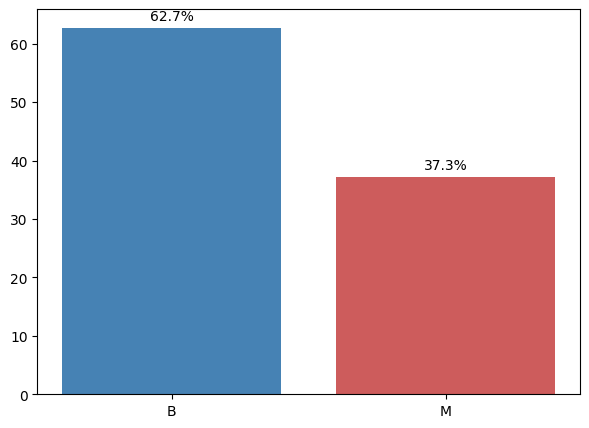

In [15]:
porcentaje_diagnostico = (
    cancer_df['diagnosis']
    .value_counts(normalize=True)
    .reindex(['B', 'M'])
    .mul(100)
)

fig, ax = plt.subplots(figsize=(7, 5))

barras = ax.bar(
    porcentaje_diagnostico.index,
    porcentaje_diagnostico.values,
    color=['steelblue', 'indianred']
)

_ = ax.bar_label(
    barras,
    labels=[f'{valor:.1f}%' for valor in porcentaje_diagnostico.values],
    padding=3
)

### Respuesta ejercicio 2

La distribución de la variable de salida es relevante porque existe una mayor cantidad de tumores benignos (62.7%) que malignos (37.3%). Aunque el desbalance no es extremo, un modelo podría favorecer la clase mayoritaria y obtener una exactitud aparentemente alta sin identificar correctamente los casos malignos. Por ello, además de la exactitud, es importante revisar métricas como la precisión y el recall, especialmente para la clase maligna.

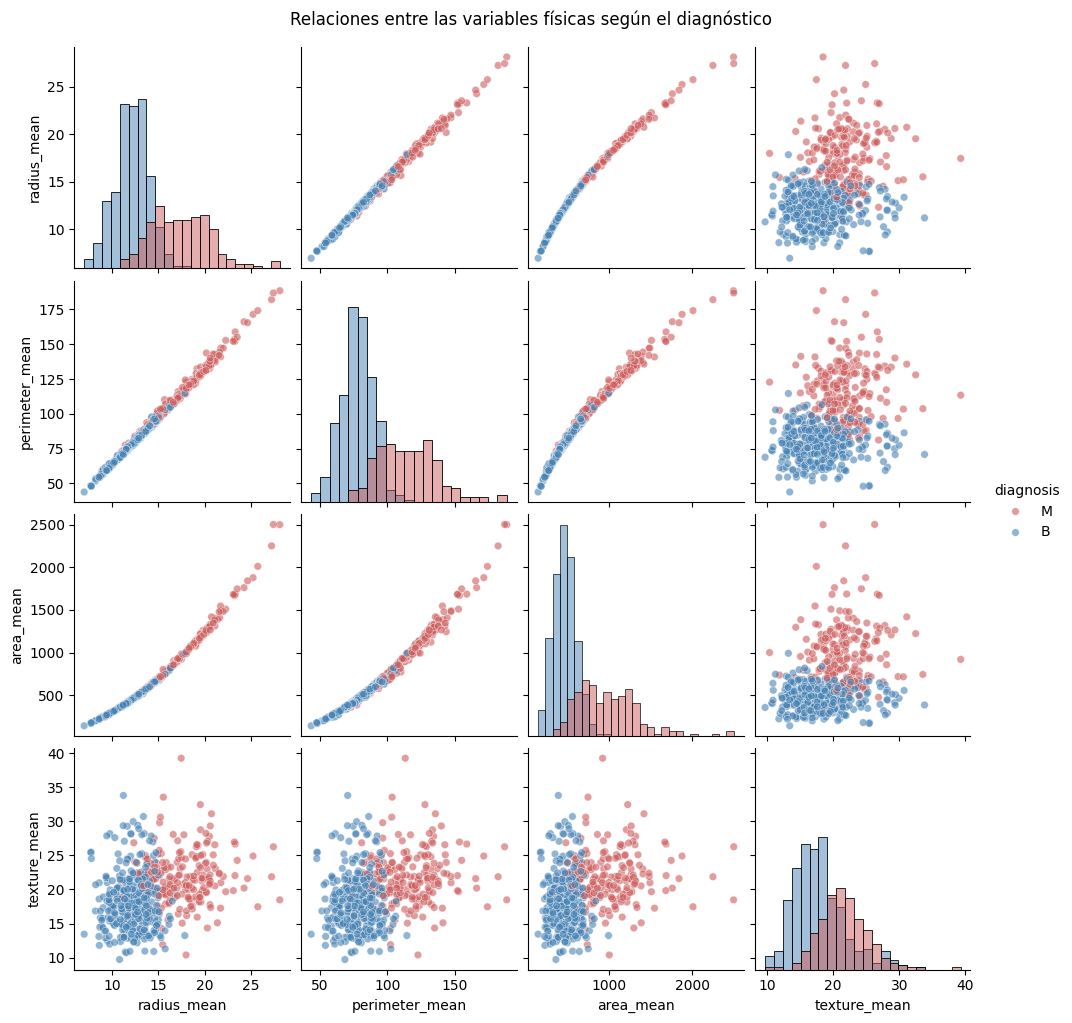

In [16]:
variables_fisicas = [
    'radius_mean',
    'perimeter_mean',
    'area_mean',
    'texture_mean'
]

sns.pairplot(
    data=cancer_df,
    vars=variables_fisicas,
    hue='diagnosis',
    palette={'B': 'steelblue', 'M': 'indianred'},
    diag_kind='hist',
    plot_kws={'alpha': 0.6, 's': 30}
)

_ = plt.suptitle(
    'Relaciones entre las variables físicas según el diagnóstico',
    y=1.02
)

### Respuesta ejercicio 2

El radio, el perímetro y el área presentan relaciones positivas muy fuertes. Al aumentar el radio también aumentan el perímetro y el área, aunque la relación con el área muestra una forma curva debido a que esta crece de manera no lineal con el tamaño. La textura presenta una relación más débil con las demás variables físicas. Los tumores malignos tienden a registrar valores mayores de radio, perímetro y área que los benignos, por lo que estas variables permiten distinguir parcialmente ambos diagnósticos. En la textura existe una mayor superposición entre las clases, por lo que parece tener menor capacidad de sepración por sí sola.

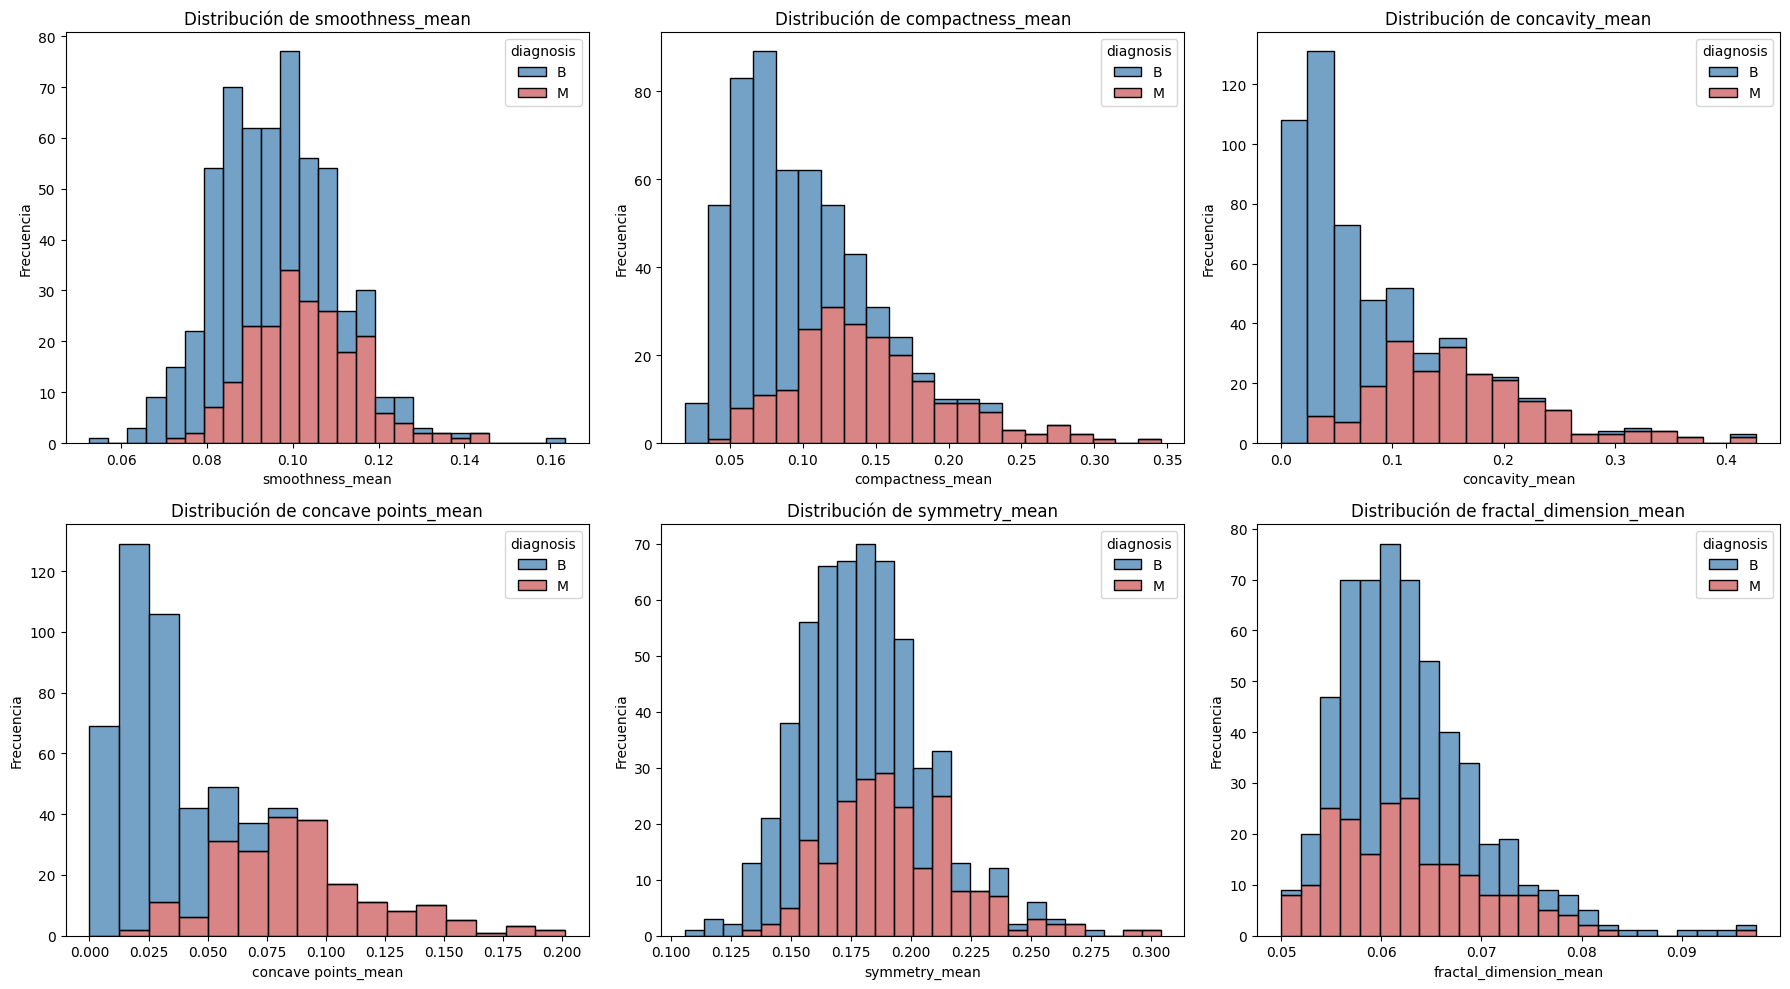

In [17]:
variables_morfologicas = [
    'smoothness_mean',
    'compactness_mean',
    'concavity_mean',
    'concave points_mean',
    'symmetry_mean',
    'fractal_dimension_mean'
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for columna, ax in zip(variables_morfologicas, axes.flatten()):
  sns.histplot(
      data=cancer_df,
      x=columna,
      hue='diagnosis',
      hue_order=['B', 'M'],
      multiple='stack',
      palette={'B': 'steelblue', 'M': 'indianred'},
      ax=ax
  )

  ax.set_title(f'Distribución de {columna}')
  ax.set_xlabel(columna)
  ax.set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

### Respuesta ejercicio 2

Las variables **concavity_mean** y **concave points_mean** muestran la mejor capacidad para distinguir entre las clases, ya que los tumores malignos se concentran en valores mayores y existe una separación más clara respecto a los benignos, **compactness_mean**, **symmetry_mean** y **fractak_dimension_mean** presentan un solapamiento considerable, por lo que individualmente parecen ser discriminadores menos efectivos.

3. Antes de realizar el análisis de correlación, crea una copia del dataframe (`cancer_copy`).
* Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos. La alta correlación entre las variables del conjunto _mean y _worst es inevitable, ya que las columnas _worst representan esencialmente los valores máximos de las mismas características medidas en _mean. Elimina las columnas _worst para simplificar el análisis.
* Imprime nuevamente los pares con correlación superior a 0.9. Como habías observado previamente, existen relaciones lineales entre `radius`, `perimeter` y `area`, por lo que era esperable encontrar altas correlaciones. De estas tres medidas, ¿cuál mantendrías y por qué? Elimina todas las variables de los otros dos conjuntos.
* Dibuja un mapa de calor con la matriz de correlación para identificar si prevalece alguna correlación relevante. Si eliminas alguna otra variable, justifica tu elección.

In [18]:
cancer_copy = cancer_df.copy()

def obtener_correlaciones_altas(dataframe, limite=0.9):
  matriz_correlacion = dataframe.corr(numeric_only=True)

  triangulo_superior = np.triu(
      np.ones_like(matriz_correlacion, dtype=bool),
      k=1
  )

  pares = (
      matriz_correlacion
      .where(triangulo_superior)
      .stack()
      .reset_index()
  )

  pares.columns = ['variable_1', 'variable_2', 'correlacion']

  return(
      pares[pares['correlacion'] > limite]
      .sort_values('correlacion', ascending=False)
      .reset_index(drop=True)
  )

print('Correlaciones superiores a 0.9: ')
display(obtener_correlaciones_altas(cancer_copy))

columnas_worst = [
    columna for columna in cancer_copy.columns
    if columna.endswith('_worst')
]

cancer_copy = cancer_copy.drop(columns=columnas_worst)

print('\nCorrelaciones superiores a 0.9 después de eliminar las variables _worst: ')
display(obtener_correlaciones_altas(cancer_copy))

Correlaciones superiores a 0.9: 


,variable_1,variable_2,correlacion
0,radius_mean,perimeter_mean,0.997855
1,radius_worst,perimeter_worst,0.993708
2,radius_mean,area_mean,0.987357
3,perimeter_mean,area_mean,0.986507
4,radius_worst,area_worst,0.984015
5,perimeter_worst,area_worst,0.977578
6,radius_se,perimeter_se,0.972794
7,perimeter_mean,perimeter_worst,0.970387
8,radius_mean,radius_worst,0.969539
9,perimeter_mean,radius_worst,0.969476



Correlaciones superiores a 0.9 después de eliminar las variables _worst: 


,variable_1,variable_2,correlacion
0,radius_mean,perimeter_mean,0.997855
1,radius_mean,area_mean,0.987357
2,perimeter_mean,area_mean,0.986507
3,radius_se,perimeter_se,0.972794
4,radius_se,area_se,0.951830
5,perimeter_se,area_se,0.937655
6,concavity_mean,concave points_mean,0.921391


Correlaciones superiores a 0.9 después de eliminar perimeter y area: 


,variable_1,variable_2,correlacion
0,concavity_mean,concave points_mean,0.921391


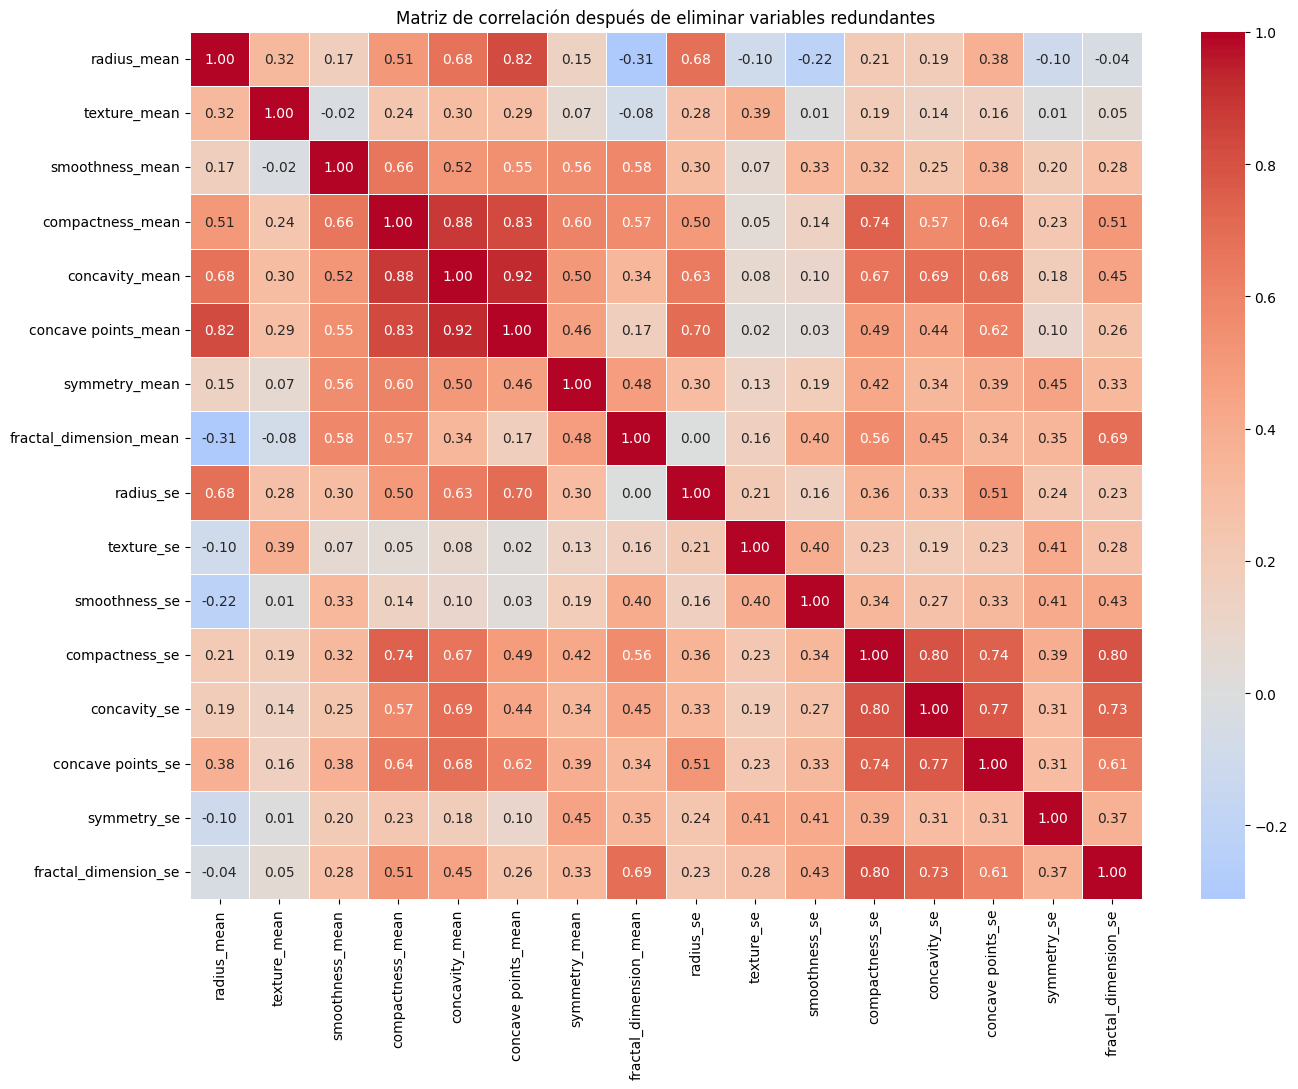

In [19]:
columnas_redundantes = [
    columna for columna in cancer_copy.columns
    if columna.startswith('perimeter_')
    or columna.startswith('area_')
]

cancer_copy = cancer_copy.drop(columns=columnas_redundantes)

print('Correlaciones superiores a 0.9 después de eliminar perimeter y area: ')
display(obtener_correlaciones_altas(cancer_copy))

matriz_correlacion = cancer_copy.corr(numeric_only=True)

plt.figure(figsize=(14, 11))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Matriz de correlación después de eliminar variables redundantes')
plt.tight_layout()
plt.show()

In [20]:
diagnostico_binario = cancer_copy['diagnosis'].map({
    'B': 0,
    'M': 1
})

relacion_diagnostico = cancer_copy[
    ['concavity_mean', 'concave points_mean']
].corrwith(diagnostico_binario).to_frame('correlacion_diagnostico')

display(relacion_diagnostico)

cancer_copy = cancer_copy.drop(columns=['concavity_mean'])

print('Correlaciones superiores a 0.9 después de la eliminación final: ')
display(obtener_correlaciones_altas(cancer_copy))

,correlacion_diagnostico
concavity_mean,0.696360
concave points_mean,0.776614


Correlaciones superiores a 0.9 después de la eliminación final: 


,variable_1,variable_2,correlacion


4. Separa las variables predictoras `X` de la variable de salida `y`, usando el dataframe original `cancer_df` (la eliminación de variables correlacionadas se integrará en el pipeline).
* Codifica `diagnosis` como 0 (Benigno) y 1 (Maligno).
* Divide el conjunto de datos en entrenamiento y prueba (80:20), usando `random_state=1` para garantizar reproducibilidad.
* Para evaluar los modelos que se construirán, define una función llamada `evaluate_model` que reciba los valores reales y las predicciones e imprima las métricas de recall, precisión y exactitud (accuracy).

In [21]:
# 1. Separar las variables predictoras (X) y la variable de salida (y) a partir de cancer_df
X = cancer_df.drop(columns=['diagnosis'])
y = cancer_df['diagnosis'].map({'B': 0, 'M': 1})

# Verificar la codificación de la variable objetivo
print("Distribución de clases codificadas en y (0 = Benigno, 1 = Maligno):")
print(y.value_counts(), "\n")

# 2. Dividir el conjunto de datos en entrenamiento (80%) y prueba (20%) con random_state=1
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=1
)

print(f"Dimensiones de X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"Dimensiones de X_test:  {X_test.shape} | y_test:  {y_test.shape}\n")

# 3. Definir la función evaluate_model para imprimir recall, precisión y exactitud
def evaluate_model(y_true, y_pred):
    rec = recall_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)

    print(f"Recall (Sensibilidad): {rec:.4f}")
    print(f"Precisión (Precision): {prec:.4f}")
    print(f"Exactitud (Accuracy):  {acc:.4f}")

Distribución de clases codificadas en y (0 = Benigno, 1 = Maligno):
diagnosis
0    357
1    212
Name: count, dtype: int64 

Dimensiones de X_train: (455, 30) | y_train: (455,)
Dimensiones de X_test:  (114, 30) | y_test:  (114,)



**Respuesta Ejercicio 4**

A partir del conjunto de datos original (`cancer_df`), se separaron las 30 variables predictoras (`X`) de la variable objetivo (`y`), codificando esta última de forma binaria como `0` para tumores benignos (357 registros) y `1` para tumores malignos (212 registros). Posteriormente, los datos se dividieron en conjuntos de entrenamiento y prueba bajo una proporción 80:20 utilizando `random_state=1` para garantizar la reproducibilidad de los experimentos, obteniendo 455 observaciones para entrenamiento y 114 para evaluación. Finalmente, se implementó la función `evaluate_model` para estandarizar el cálculo y reporte de las métricas de *Recall* (sensibilidad), *Precision* (precisión) y *Accuracy* (exactitud) en los modelos posteriores.

5. Prepara un transformador denominado `preprocessing`, usando ColumnTransformer, para borrar las columnas altamente correlacionadas (identificadas en el ejercicio 3) Asegúrate de incluir el parámetro `remainder='passthrough'` para mantener el resto de las variables.
* Crea un pipeline que integre el transformador y regresión logística para  entrenar un modelo.
* Evalúa el desempeño del modelo en el conjunto de prueba empleando la función `evaluate_model`.
* Integra los resultados en un dataframe que contenga el nombre del modelo (*Correlation_Clean*) y una columna para cada métrica calculada.

In [22]:
# Identificar las columnas altamente correlacionadas determinadas en el ejercicio 3
columnas_a_eliminar = [
    col for col in X.columns
    if col.endswith('_worst')
    or col.startswith('perimeter_')
    or col.startswith('area_')
    or col == 'concavity_mean'
]

# Preparar el transformador preprocessing manteniendo el resto de las variables
preprocessing = ColumnTransformer(
    transformers=[
        ('drop_cols', 'drop', columnas_a_eliminar)
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
)

# Crear el pipeline integrando preprocessing y regresión logística
model_pipeline = make_pipeline(
    preprocessing,
    LogisticRegression(random_state=1, max_iter=1000)
)

# Entrenar el modelo y predecir sobre el conjunto de prueba
model_pipeline.fit(X_train, y_train)
y_pred = model_pipeline.predict(X_test)

# Evaluar el desempeño usando la función evaluate_model
print("Evaluación del modelo Correlation_Clean:")
evaluate_model(y_test, y_pred)

# Integrar los resultados en el dataframe de métricas
resultados_df = pd.DataFrame(
    {
        'Recall': [recall_score(y_test, y_pred)],
        'Precision': [precision_score(y_test, y_pred)],
        'Accuracy': [accuracy_score(y_test, y_pred)]
    },
    index=pd.Index(['Correlation_Clean'], name='Model')
)

display(resultados_df)

Evaluación del modelo Correlation_Clean:
Recall (Sensibilidad): 0.7619
Precisión (Precision): 0.8889
Exactitud (Accuracy):  0.8772


,Recall,Precision,Accuracy
Model,,,
Correlation_Clean,0.761905,0.888889,0.877193


**Respuesta Ejercicio 5**

Se construyó el transformador `preprocessing` mediante `ColumnTransformer` (con `remainder='passthrough'`) para eliminar las 15 variables altamente correlacionadas identificadas en el ejercicio 3 (`_worst`, `perimeter_*`, `area_*` y `concavity_mean`), conservando las 15 variables predictoras restantes. Este transformador se integró en un *pipeline* junto con el modelo de regresión logística (`Correlation_Clean`).

Al evaluar el modelo sobre el conjunto de prueba (114 observaciones) y registrar las métricas en `resultados_df`, se obtuvieron los siguientes resultados:
* **Recall (Sensibilidad):** 0.7619 (76.19%)
* **Precisión (Precision):** 0.8889 (88.89%)
* **Exactitud (Accuracy):** 0.8772 (87.72%)

**Análisis:** Aunque el modelo logra una exactitud general del 87.72% y una buena precisión (88.89%), su sensibilidad (*recall*) de 76.19% indica que casi una cuarta parte de los tumores malignos en el conjunto de prueba no son detectados (falsos negativos). Asimismo, al entrenar la regresión logística directamente sobre variables en sus escalas originales sin normalización previa, las diferencias de magnitud entre características (por ejemplo, `radius_mean` frente a `fractal_dimension_se`) limitan el desempeño del clasificador, lo que motiva probar técnicas de escalado, reducción de dimensionalidad y normalización.

6. Una alternativa para reducir la multicolinealidad es el análisis de componentes principales. Construye un pipeline que incluya escalado estándar, PCA y regresión logística, manteniendo el número mínimo de componentes principales que expliquen al menos el 90% de la varianza.
* Entrena el modelo utilizando el conjunto de entrenamiento y evalúalo en el conjunto de prueba.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *Standard_PCA*.
* ¿Cuántos componentes principales se emplearon?

In [23]:
# Construir el pipeline con escalado estándar, PCA (>= 90% de varianza) y regresión logística
pca_pipeline = make_pipeline(
    StandardScaler(),
    PCA(n_components=0.90, random_state=1),
    LogisticRegression(random_state=1)
)

# Entrenar el modelo con el conjunto de entrenamiento y evaluar en prueba
pca_pipeline.fit(X_train, y_train)
y_pred_pca = pca_pipeline.predict(X_test)

print("Evaluación del modelo Standard_PCA:")
evaluate_model(y_test, y_pred_pca)

# Añadir los valores de las métricas al dataframe de resultados
resultados_df.loc['Standard_PCA'] = [
    recall_score(y_test, y_pred_pca),
    precision_score(y_test, y_pred_pca),
    accuracy_score(y_test, y_pred_pca)
]
display(resultados_df)

# Obtener e imprimir la cantidad de componentes principales empleados
pca_step = pca_pipeline.named_steps['pca']
n_components_used = pca_step.n_components_
varianza_acumulada = pca_step.explained_variance_ratio_.sum() * 100

print(f"\nNúmero de componentes principales empleados (>= 90% varianza): {n_components_used}")
print(f"Varianza acumulada explicada: {varianza_acumulada:.2f}%")

Evaluación del modelo Standard_PCA:
Recall (Sensibilidad): 0.9286
Precisión (Precision): 1.0000
Exactitud (Accuracy):  0.9737


,Recall,Precision,Accuracy
Model,,,
Correlation_Clean,0.761905,0.888889,0.877193
Standard_PCA,0.928571,1.000000,0.973684



Número de componentes principales empleados (>= 90% varianza): 7
Varianza acumulada explicada: 91.08%


**Respuesta Ejercicio 6**

Se emplearon **7 componentes principales** para explicar al menos el 90% de la varianza total de las 30 variables originales (alcanzando una varianza acumulada exacta del **91.08%**).

Al integrar el escalado estándar (`StandardScaler`), el análisis de componentes principales (`PCA(n_components=0.90)`) y la regresión logística dentro de un *pipeline* (`Standard_PCA`), se obtuvieron las siguientes métricas sobre el conjunto de prueba:
* **Recall (Sensibilidad):** 0.9286 (92.86%)
* **Precisión (Precision):** 1.0000 (100.00%)
* **Exactitud (Accuracy):** 0.9737 (97.37%)

**Análisis:** El modelo `Standard_PCA` supera significativamente al modelo base sin escalar (`Correlation_Clean`), incrementando la exactitud de 87.72% a 97.37% y elevando la sensibilidad (*recall*) en más de 16 puntos porcentuales (de 76.19% a 92.86%), además de lograr una precisión perfecta (ningún caso benigno fue clasificado erróneamente como maligno). Al transformar las 30 características estandarizadas en 7 componentes ortogonales no correlacionados, PCA elimina por completo la multicolinealidad conservando la mayor parte de la información relevante del conjunto de datos, aunque a costa de perder interpretabilidad directa sobre las variables clínicas individuales.

7. Como intento de mejorar las métricas del modelo, y dado que todas las variables presentan sesgo, aplica una normalización utilizando Yeo-Johnson. Para ello:
* Crea un pipeline que integre el transformador `preprocessing`, una transformación Yeo-Johnson y regresión logística.
* Entrena el modelo utilizando el conjunto de entrenamiento y evalúalo en el conjunto de prueba.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *Correlation_Yeo*.

In [24]:
# Construir el pipeline integrando preprocessing, transformación Yeo-Johnson y regresión logística
yeo_pipeline = make_pipeline(
    preprocessing,
    PowerTransformer(method='yeo-johnson'),
    LogisticRegression(random_state=1)
)

# Entrenar el modelo utilizando el conjunto de entrenamiento y evaluarlo en prueba
yeo_pipeline.fit(X_train, y_train)
y_pred_yeo = yeo_pipeline.predict(X_test)

print("Evaluación del modelo Correlation_Yeo:")
evaluate_model(y_test, y_pred_yeo)

# Añadir los valores de las métricas obtenidas al dataframe de resultados
resultados_df.loc['Correlation_Yeo'] = [
    recall_score(y_test, y_pred_yeo),
    precision_score(y_test, y_pred_yeo),
    accuracy_score(y_test, y_pred_yeo)
]

display(resultados_df)

Evaluación del modelo Correlation_Yeo:
Recall (Sensibilidad): 0.9524
Precisión (Precision): 1.0000
Exactitud (Accuracy):  0.9825


,Recall,Precision,Accuracy
Model,,,
Correlation_Clean,0.761905,0.888889,0.877193
Standard_PCA,0.928571,1.000000,0.973684
Correlation_Yeo,0.952381,1.000000,0.982456


**Respuesta Ejercicio 7**

Se construyó un *pipeline* (`Correlation_Yeo`) que integra el transformador de eliminación de variables altamente correlacionadas (`preprocessing`), la normalización de potencia `PowerTransformer(method='yeo-johnson')` y el clasificador de regresión logística. Tras entrenar el modelo con el conjunto de entrenamiento y evaluarlo en el conjunto de prueba, se registraron las siguientes métricas en `resultados_df`:
* **Recall (Sensibilidad):** 0.9524 (95.24%)
* **Precisión (Precision):** 1.0000 (100.00%)
* **Exactitud (Accuracy):** 0.9825 (98.25%)

**Análisis:** El modelo `Correlation_Yeo` obtiene el mejor desempeño global de los tres enfoques evaluados hasta el momento. Dado que todas las variables numéricas del conjunto de datos presentaban asimetría positiva (sesgo), la transformación de Yeo-Johnson logra aproximar sus distribuciones a una forma normal y estandarizar sus escalas (media cero y varianza unitaria). Esto permite que la regresión logística ajuste una frontera de decisión mucho más efectiva, elevando la sensibilidad (*recall*) de 76.19% (`Correlation_Clean`) y 92.86% (`Standard_PCA`) hasta **95.24%** —reduciendo al mínimo los falsos negativos en tumores malignos—, manteniendo una precisión perfecta del **100%** y alcanzando una exactitud del **98.25%**, todo ello conservando la interpretabilidad directa de las 15 variables seleccionadas.

8. Del modelo anterior, obtén los nombres de los predictores empleados. ¿Cuántos son?
* Revisa los coeficientes del modelo de regresión logística y analiza su magnitud para identificar las variables 10 más influyentes.
* Grafícalas en un barplot horizontal, mostrando el valor del coeficiente y respetando su signo.

In [25]:
# Nombres de los predictores usados por el modelo (despues de eliminar columnas)
predictores = preprocessing.get_feature_names_out()
print(len(predictores), 'predictores:')
print(list(predictores))

15 predictores:
['radius_mean', 'texture_mean', 'smoothness_mean', 'compactness_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se']


In [26]:
# Coeficientes de la regresion logistica y las 10 variables de mayor magnitud
coeficientes = pd.Series(yeo_pipeline[-1].coef_[0], index=predictores)
top10 = coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index).head(10)
top10

,0
concave points_mean,2.467117
texture_mean,1.906850
radius_mean,1.379170
radius_se,1.320211
concavity_se,1.012023
symmetry_mean,0.783896
symmetry_se,-0.720241
compactness_se,-0.697009
compactness_mean,0.624829
concave points_se,-0.562104


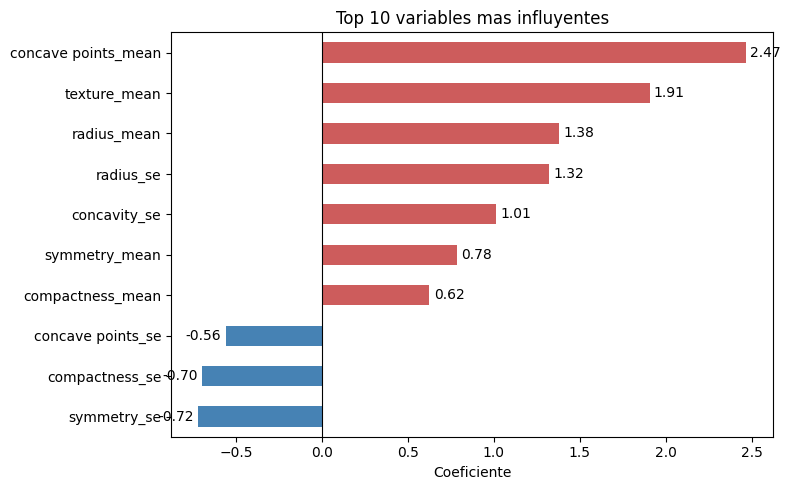

In [27]:
top10_ord = top10.sort_values()
colores = ['indianred' if v > 0 else 'steelblue' for v in top10_ord]

ax = top10_ord.plot.barh(color=colores, figsize=(8, 5))
ax.bar_label(ax.containers[0], fmt='%.2f', padding=3)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Coeficiente')
ax.set_title('Top 10 variables mas influyentes')
plt.tight_layout()
plt.show()

### Respuesta ejercicio 8

El modelo emplea **15 predictores** (las variables `_mean` y `_se` que quedaron tras eliminar `_worst`, `perimeter_*`, `area_*` y `concavity_mean`).

Como las variables pasaron por Yeo-Johnson (media 0 y varianza 1), los coeficientes son comparables entre si. Las mas influyentes son `concave points_mean` (2.47), `texture_mean` (1.91), `radius_mean` (1.38), `radius_se` (1.32) y `concavity_se` (1.01), todas con signo positivo: al aumentar su valor crece la probabilidad de que el tumor sea maligno. Con signo negativo destacan `symmetry_se`, `compactness_se` y `concave points_se`, que reducen esa probabilidad (ceteris paribus).

9. Imprime el dataframe de resultados.
* Dibuja la matriz de confusión del mejor modelo. ¿Qué significa cada valor en ella?
* Dibuja la curva ROC del mismo modelo y describe lo que indica sobre su capacidad para distinguir entre clases.

In [28]:
display(resultados_df)

,Recall,Precision,Accuracy
Model,,,
Correlation_Clean,0.761905,0.888889,0.877193
Standard_PCA,0.928571,1.000000,0.973684
Correlation_Yeo,0.952381,1.000000,0.982456


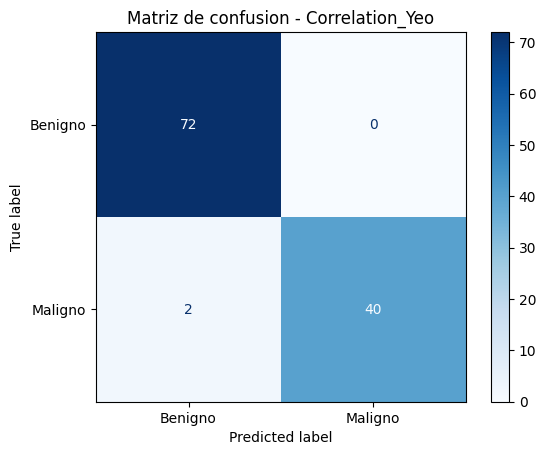

In [29]:
# El mejor modelo es Correlation_Yeo (mayor recall y exactitud)
ConfusionMatrixDisplay.from_estimator(
    yeo_pipeline, X_test, y_test,
    display_labels=['Benigno', 'Maligno'], cmap='Blues')
plt.title('Matriz de confusion - Correlation_Yeo')
plt.show()

### Respuesta ejercicio 9

El mejor modelo es **Correlation_Yeo** (recall 0.9524, precision 1.0, exactitud 0.9825). En su matriz de confusion:
* **Verdaderos negativos (72):** benignos clasificados correctamente como benignos.
* **Falsos positivos (0):** benignos clasificados como malignos; por eso la precision es 100%.
* **Falsos negativos (2):** malignos que el modelo clasifico como benignos; es el error mas grave y explica el recall de 95.24%.
* **Verdaderos positivos (40):** malignos detectados correctamente.

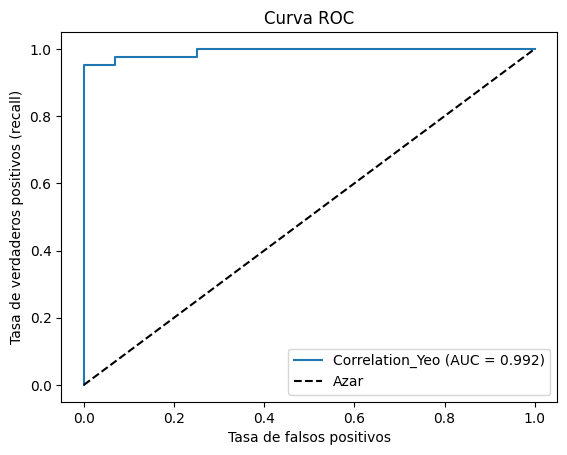

In [30]:
y_prob = yeo_pipeline.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label=f'Correlation_Yeo (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Azar')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos (recall)')
plt.title('Curva ROC')
plt.legend()
plt.show()

La curva ROC se pega a la esquina superior izquierda y el **AUC es 0.992**: el modelo logra una alta tasa de verdaderos positivos con una tasa de falsos positivos casi nula. Esto indica que separa muy bien tumores benignos de malignos, y que la probabilidad que asigna a un tumor maligno elegido al azar es mayor que la de uno benigno el 99.2% de las veces. Un modelo al azar daria AUC = 0.5 (linea punteada).

10. Grafica la distribución de las probabilidades predichas de la clase positiva (Maligno, 1) usando histogramas superpuestos, diferenciando con colores las clases reales Benigno (B) y Maligno (M).
* ¿Cuál es el umbral (*threshold*) por defecto que utiliza scikit-learn para convertir probabilidades en predicciones binarias?
* En un modelo de diagnóstico médico, ¿cuál consideras que es la métrica más importante?
* ¿Cómo cambiarías (disminuir / aumentar) el *threshold*? ¿Por qué?

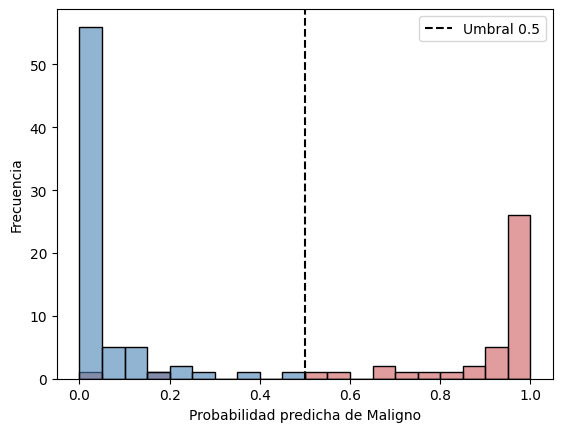

In [31]:
y_test_label = y_test.map({0: 'B', 1: 'M'})
sns.histplot(x=y_prob, hue=y_test_label, hue_order=['B', 'M'], bins=20,
             palette={'B': 'steelblue', 'M': 'indianred'}, alpha=0.6)
plt.axvline(0.5, color='black', ls='--', label='Umbral 0.5')
plt.xlabel('Probabilidad predicha de Maligno')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

### Respuesta ejercicio 10

* **Umbral por defecto:** scikit-learn clasifica como positivo (maligno) cuando la probabilidad es **>= 0.5**.
* **Metrica mas importante:** el **recall (sensibilidad)** de la clase maligna. Un falso negativo (un cancer no detectado) retrasa el tratamiento y es mucho mas costoso que un falso positivo, que normalmente se resuelve con estudios adicionales (aunque la precision tambien debe vigilarse para no generar biopsias innecesarias).
* **Cambio del umbral:** lo **disminuiria** (por ejemplo a 0.3 o 0.4). Asi se clasifican como malignos mas casos dudosos, lo que sube el recall y reduce los falsos negativos, a costa de mas falsos positivos. En el histograma, los dos malignos mal clasificados tienen probabilidades menores a 0.5 y se recuperarian con un umbral menor; como los benignos casi todos estan por debajo de 0.2-0.3, el costo en falsos positivos seria pequeno.

---

**Declaración de uso de IA**

Anthropic. (2026). Claude (Claude Sonnet 5.5) [Modelo de lenguaje de gran tamaño]. https://claude.ai/

Se utilizó Claude como apoyo para consultar ideas y sugerencias de código en Pandas, Matplotlib, Seaborn y scikit-learn, y para orientar la redacción de interpretaciones en el análisis de breast_cancer.csv. El código y las respuestas fueron revisados, modificados y mejorados por el autor.

---